# Predicting Population Decline with Supervised Learning
**CMP6202 – Artificial Intelligence and Machine Learning Project (2026–27)**
Student ID: 23187763

This notebook predicts whether a country's population is **shrinking** (annual growth rate < 0) in a given year from its demographic profile, using the UN *World Population Prospects 2024* (Demographic Indicators, Medium variant).

Three classifiers are compared: Logistic Regression, a Decision Tree and a Random Forest. The data is split **by year** to prevent temporal leakage.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
DATA_PATH = "data/WPP2024_Demographic_Indicators_Medium.csv.gz"
FIG_DIR = "figures"
import os; os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

## 1. Load and filter the data

In [2]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Raw shape:", raw.shape)

# Keep individual countries/areas only (drop World, regions, income groups -> they double-count people)
df = raw[raw["LocTypeName"] == "Country/Area"].copy()
# Keep estimates only: 2024+ are UN *projections*, i.e. model output rather than observed data
df = df[df["Time"] <= 2023]
# Drop micro-states (< 100,000 people at their peak): tiny denominators make rates very noisy
peak_pop = df.groupby("Location")["TPopulation1July"].transform("max")   # thousands
df = df[peak_pop >= 100].copy()
print("Countries:", df["Location"].nunique(), "| Years:", df["Time"].min(), "-", df["Time"].max(),
      "| Rows:", len(df))

Raw shape: (84360, 67)
Countries: 201 | Years: 1950 - 2023 | Rows: 14874


## 2. Target variable and leakage control

In [3]:
# Target: 1 if the population shrank in that year, else 0
df["Declining"] = (df["PopGrowthRate"] < 0).astype(int)

# Columns that define (or arithmetically reconstruct) the target are excluded.
# Growth = natural change (births - deaths) + net migration, so all of these leak the answer.
LEAKY = ["TPopulation1Jan", "TPopulation1July", "TPopulationMale1July", "TPopulationFemale1July",
         "PopChange", "PopGrowthRate", "DoublingTime", "NatChange", "NatChangeRT",
         "Births", "Deaths", "DeathsMale", "DeathsFemale", "CBR", "CDR",
         "NetMigrations", "CNMR", "InfantDeaths", "Under5Deaths", "Births1519", "LBsurvivingAge1"]

BASE_FEATURES = ["TFR", "NRR", "MAC", "SRB", "MedianAgePop", "PopSexRatio", "PopDensity",
                 "LEx", "LE15", "LE65", "LE80", "IMR", "Q5", "Q0040", "Q0060", "Q1550", "Q1560"]
print(df[BASE_FEATURES + ["Declining"]].describe().T.round(2))

                count    mean      std     min     25%     50%     75%       max
TFR           14874.0    4.13     2.04    0.66    2.20    3.84    6.09      8.86
NRR           14874.0    1.65     0.67    0.16    1.03    1.66    2.21      3.48
MAC           14874.0   28.74     1.44   23.69   27.78   28.88   29.74     33.42
SRB           14874.0  105.02     1.85  100.30  103.80  105.00  106.10    117.80
MedianAgePop  14874.0   23.18     7.67   12.62   17.02   20.10   28.56     48.96
PopSexRatio   14874.0  100.20    14.49   72.52   95.07   98.47  101.69    319.85
PopDensity    14874.0  218.47  1022.91    0.05   16.73   57.91  136.64  22309.73
LEx           14874.0   62.85    12.33   10.99   54.38   65.45   72.20     85.51
LE15          14874.0   54.45     6.74    6.93   49.75   55.08   59.04     70.72
LE65          14874.0   13.80     2.52    3.01   12.00   13.28   15.08     23.19
LE80          14874.0    6.08     1.30    2.05    5.20    5.77    6.70     11.82
IMR           14874.0   60.6

## 3. Feature engineering (past information only)

In [4]:
df = df.sort_values(["Location", "Time"])
g = df.groupby("Location")
# Average net migration rate over the PREVIOUS five years (shift(1) => year t is never used)
df["CNMR_prev5"] = g["CNMR"].transform(lambda s: s.shift(1).rolling(5).mean())
# Five-year change in fertility and in median age (momentum of ageing)
df["TFR_change5"] = df["TFR"] - g["TFR"].shift(5)
df["MedianAge_change5"] = df["MedianAgePop"] - g["MedianAgePop"].shift(5)
# Female-male life expectancy gap
df["LEx_gap"] = df["LExFemale"] - df["LExMale"]

ENG_FEATURES = ["CNMR_prev5", "TFR_change5", "MedianAge_change5", "LEx_gap"]
ALL_FEATURES = BASE_FEATURES + ENG_FEATURES

# The lagged features need 5 previous years, so modelling starts in 1955
model_df = df[df["Time"] >= 1955].dropna(subset=ALL_FEATURES).reset_index(drop=True)
print("Modelling rows:", len(model_df), "| Missing values left:", model_df[ALL_FEATURES].isna().sum().sum())

Modelling rows: 13869 | Missing values left: 0


## 4. Temporal train/test split

Train: 9849 rows (71%), positive rate 0.052
Test : 4020 rows (29%), positive rate 0.155


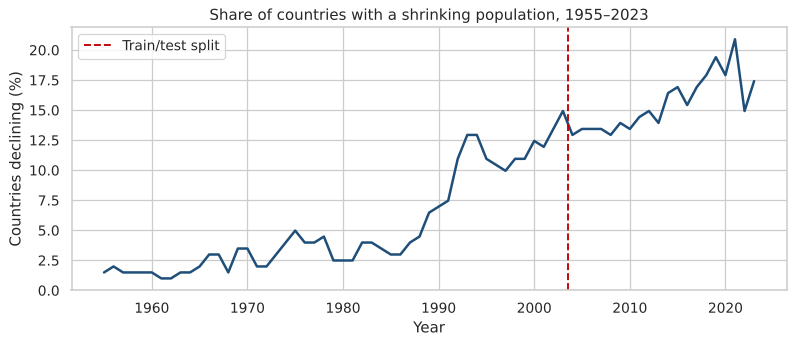

In [5]:
SPLIT_YEAR = 2003   # train: 1955-2003, test: 2004-2023
train = model_df[model_df["Time"] <= SPLIT_YEAR].sort_values("Time").reset_index(drop=True)
test  = model_df[model_df["Time"] >  SPLIT_YEAR].sort_values("Time").reset_index(drop=True)
print(f"Train: {len(train)} rows ({len(train)/len(model_df):.0%}), positive rate {train.Declining.mean():.3f}")
print(f"Test : {len(test)} rows ({len(test)/len(model_df):.0%}), positive rate {test.Declining.mean():.3f}")

share = model_df.groupby("Time")["Declining"].mean() * 100
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(share.index, share.values, color="#1f4e79", lw=2)
ax.axvline(SPLIT_YEAR + 0.5, color="#c00000", ls="--", label="Train/test split")
ax.set_title("Share of countries with a shrinking population, 1955–2023")
ax.set_xlabel("Year"); ax.set_ylabel("Countries declining (%)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig1_share_declining.png", dpi=150); plt.show()

## 5. Exploratory data analysis (training set only)

In [6]:
# Data quality checks
print("Duplicate country-years:", train.duplicated(["Location", "Time"]).sum())
print("Nulls in features:", train[ALL_FEATURES].isna().sum().sum())
q = train[BASE_FEATURES].quantile([0.01, 0.99]).T
print(q.round(2))

Duplicate country-years: 0
Nulls in features: 0
                0.01     0.99
TFR             1.26     7.93
NRR             0.60     3.13
MAC            24.92    31.22
SRB           101.10   109.45
MedianAgePop   13.97    37.40
PopSexRatio    83.57   148.67
PopDensity      0.80  3936.77
LEx            32.87    78.89
LE15           38.42    64.51
LE65            9.34    18.36
LE80            3.76     8.57
IMR             4.43   207.30
Q5              5.47   365.30
Q0040          23.69   571.94
Q0060          86.46   728.82
Q1550          32.87   421.77
Q1560          78.36   580.42


Declining
Growing      9334
Declining     515
Name: count, dtype: int64


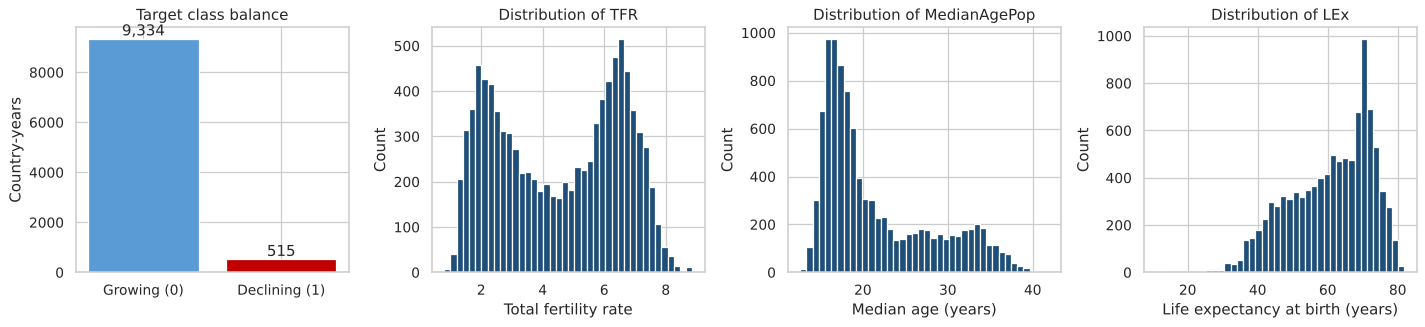

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
counts = train["Declining"].value_counts().sort_index()
axes[0].bar(["Growing (0)", "Declining (1)"], counts.values, color=["#5b9bd5", "#c00000"])
for i, v in enumerate(counts.values): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
axes[0].set_title("Target class balance"); axes[0].set_ylabel("Country-years")
for ax, col, lab in zip(axes[1:], ["TFR", "MedianAgePop", "LEx"],
                        ["Total fertility rate", "Median age (years)", "Life expectancy at birth (years)"]):
    ax.hist(train[col], bins=40, color="#1f4e79", edgecolor="white")
    ax.set_title(f"Distribution of {col}"); ax.set_xlabel(lab); ax.set_ylabel("Count")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_uni.png", dpi=150); plt.show()
print(counts.rename({0: "Growing", 1: "Declining"}))

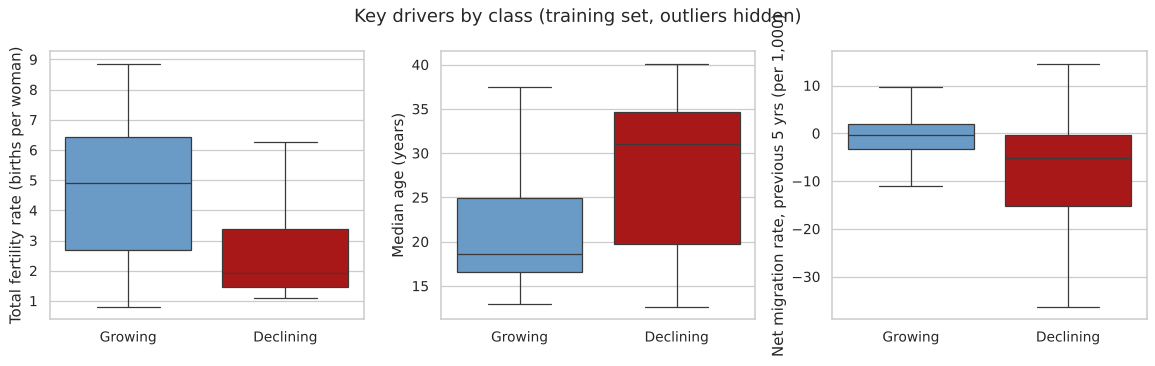

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, lab in zip(axes, ["TFR", "MedianAgePop", "CNMR_prev5"],
                        ["Total fertility rate (births per woman)", "Median age (years)",
                         "Net migration rate, previous 5 yrs (per 1,000)"]):
    sns.boxplot(data=train, x="Declining", y=col, ax=ax, hue="Declining",
                palette=["#5b9bd5", "#c00000"], legend=False, showfliers=False)
    ax.set_xticks([0, 1], ["Growing", "Declining"]); ax.set_xlabel(""); ax.set_ylabel(lab)
fig.suptitle("Key drivers by class (training set, outliers hidden)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig2_boxplots.png", dpi=150); plt.show()

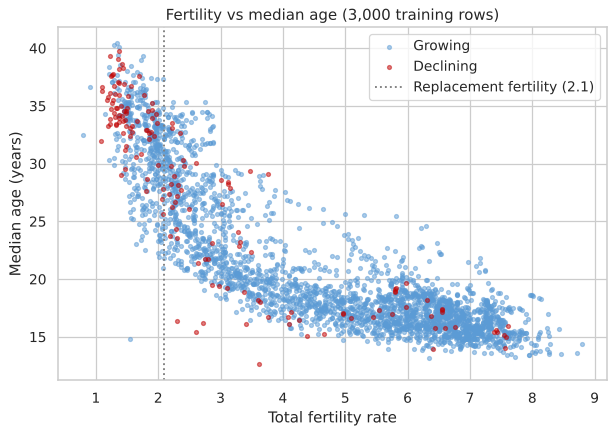

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
s = train.sample(3000, random_state=RANDOM_STATE)
for lab, colr, name in [(0, "#5b9bd5", "Growing"), (1, "#c00000", "Declining")]:
    d = s[s.Declining == lab]
    ax.scatter(d.TFR, d.MedianAgePop, s=10, alpha=0.5, c=colr, label=name)
ax.axvline(2.1, color="grey", ls=":", label="Replacement fertility (2.1)")
ax.set_xlabel("Total fertility rate"); ax.set_ylabel("Median age (years)")
ax.set_title("Fertility vs median age (3,000 training rows)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig3_tfr_vs_age.png", dpi=150); plt.show()

MedianAgePop         0.241
NRR                 -0.231
LEx_gap              0.217
MAC                 -0.210
TFR                 -0.207
CNMR_prev5          -0.157
IMR                 -0.129
MedianAge_change5    0.127
SRB                  0.122
Q5                  -0.117
PopSexRatio         -0.106
Q0040               -0.096
LEx                  0.095
Q0060               -0.081
LE65                 0.069
LE80                 0.064
TFR_change5         -0.050
LE15                 0.048
PopDensity           0.043
Q1560               -0.038
Q1550               -0.037
Name: Declining, dtype: float64


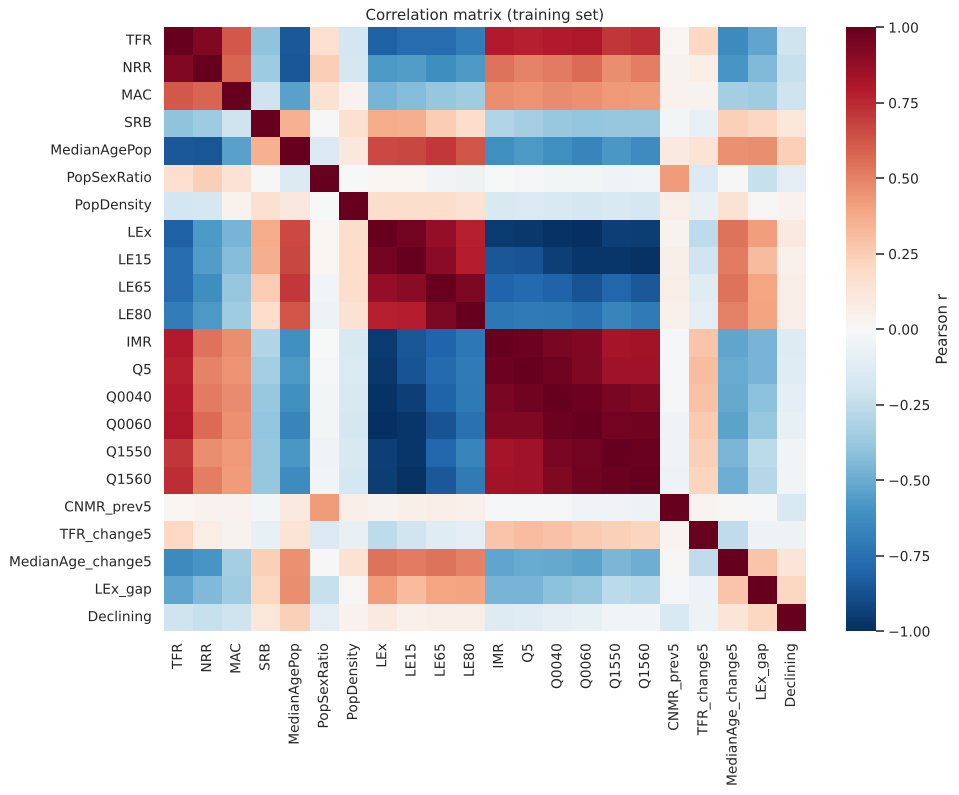

In [10]:
corr = train[ALL_FEATURES + ["Declining"]].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Pearson r"})
ax.set_title("Correlation matrix (training set)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig4_corr.png", dpi=150); plt.show()
print(corr["Declining"].drop("Declining").sort_values(key=abs, ascending=False).round(3))

## 6. Models and temporal cross-validation

In [11]:
def year_folds(frame, n_splits=5):
    """Expanding-window CV on whole years (TimeSeriesSplit logic applied to years, not rows)."""
    years = np.sort(frame["Time"].unique())
    chunks = np.array_split(years, n_splits + 1)
    folds = []
    for k in range(1, n_splits + 1):
        tr_years = np.concatenate(chunks[:k]); va_years = chunks[k]
        folds.append((np.where(frame["Time"].isin(tr_years))[0],
                      np.where(frame["Time"].isin(va_years))[0]))
    return folds

CV_FOLDS = year_folds(train)
for i, (a, b) in enumerate(CV_FOLDS, 1):
    print(f"Fold {i}: train {train.Time[a].min()}-{train.Time[a].max()}  validate {train.Time[b].min()}-{train.Time[b].max()}")

def make_models():
    return {
        "Logistic Regression": Pipeline([("scale", StandardScaler()),
                                         ("clf", LogisticRegression(class_weight="balanced", max_iter=5000,
                                                                    random_state=RANDOM_STATE))]),
        "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(class_weight="balanced", n_estimators=300,
                                                n_jobs=-1, random_state=RANDOM_STATE),
    }

def scores(y, pred, prob):
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred), "ROC-AUC": roc_auc_score(y, prob)}

Fold 1: train 1955-1963  validate 1964-1971
Fold 2: train 1955-1971  validate 1972-1979
Fold 3: train 1955-1979  validate 1980-1987
Fold 4: train 1955-1987  validate 1988-1995
Fold 5: train 1955-1995  validate 1996-2003


### 6.1 Baseline models (base features, default hyper-parameters)

In [12]:
X_tr, y_tr = train[BASE_FEATURES], train["Declining"]
X_te, y_te = test[BASE_FEATURES], test["Declining"]
baseline, seen, base_models = {}, {}, {}
for name, m in make_models().items():
    base_models[name] = m
    m.fit(X_tr, y_tr)
    seen[name] = scores(y_tr, m.predict(X_tr), m.predict_proba(X_tr)[:, 1])
    baseline[name] = scores(y_te, m.predict(X_te), m.predict_proba(X_te)[:, 1])
print("SEEN (training) data:"); print(pd.DataFrame(seen).T.round(3))
print("\nUNSEEN (test) data:"); print(pd.DataFrame(baseline).T.round(3))

SEEN (training) data:
                     Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression     0.775      0.154   0.736  0.255    0.845
Decision Tree           1.000      1.000   1.000  1.000    1.000
Random Forest           0.999      0.979   1.000  0.989    1.000

UNSEEN (test) data:
                     Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression     0.745      0.353   0.770  0.484    0.818
Decision Tree           0.851      0.544   0.278  0.368    0.618
Random Forest           0.876      0.834   0.250  0.384    0.871


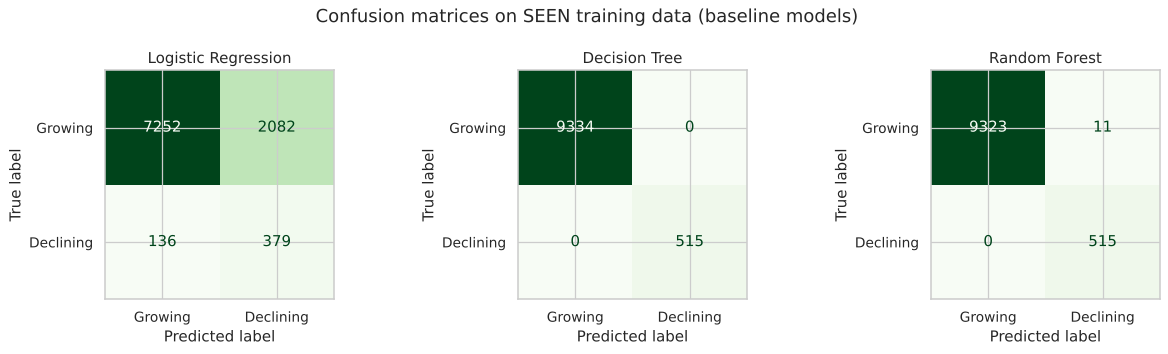

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, m) in zip(axes, base_models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_tr, y_tr, display_labels=["Growing", "Declining"],
                                          cmap="Greens", ax=ax, colorbar=False)
    ax.set_title(name)
plt.suptitle("Confusion matrices on SEEN training data (baseline models)"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig_seen_cm.png", dpi=150); plt.show()

In [14]:
# Temporal CV vs shuffled k-fold on the training set (F1)
cv_rows = []
for name, m in make_models().items():
    t = cross_val_score(m, X_tr, y_tr, cv=CV_FOLDS, scoring="f1")
    r = cross_val_score(m, X_tr, y_tr, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="f1")
    cv_rows.append({"Model": name, "Temporal CV F1 (mean)": t.mean(), "Temporal CV F1 (sd)": t.std(),
                    "Shuffled 5-fold F1 (mean)": r.mean()})
cv_table = pd.DataFrame(cv_rows).set_index("Model"); print(cv_table.round(3))

                     Temporal CV F1 (mean)  Temporal CV F1 (sd)  Shuffled 5-fold F1 (mean)
Model                                                                                     
Logistic Regression                  0.214                0.143                      0.254
Decision Tree                        0.211                0.134                      0.632
Random Forest                        0.250                0.210                      0.754


### 6.2 Improvement: engineered features + grid search with temporal CV

In [15]:
GRIDS = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10]},
    "Decision Tree": {"max_depth": [4, 6, 8, 12, None], "min_samples_leaf": [1, 10, 50]},
    "Random Forest": {"n_estimators": [300], "max_depth": [6, 10, None],
                      "min_samples_leaf": [1, 10], "max_features": ["sqrt", 0.5]},
}
X_tr2, X_te2 = train[ALL_FEATURES], test[ALL_FEATURES]
tuned, final, best_params, cv_best, seen_tuned = {}, {}, {}, {}, {}
for name, m in make_models().items():
    gs = GridSearchCV(m, GRIDS[name], cv=CV_FOLDS, scoring="f1", n_jobs=-1)
    gs.fit(X_tr2, y_tr)
    tuned[name] = gs.best_estimator_; best_params[name] = gs.best_params_; cv_best[name] = gs.best_score_
    final[name] = scores(y_te, gs.predict(X_te2), gs.predict_proba(X_te2)[:, 1])
    seen_tuned[name] = scores(y_tr, gs.predict(X_tr2), gs.predict_proba(X_tr2)[:, 1])
    print(f"{name}: best {gs.best_params_}  CV F1={gs.best_score_:.3f}")
print("TUNED models on SEEN training data:"); print(pd.DataFrame(seen_tuned).T.round(3))
print("\nTUNED models on UNSEEN test data:"); final_table = pd.DataFrame(final).T; print(final_table.round(3))

Logistic Regression: best {'clf__C': 1}  CV F1=0.370
Decision Tree: best {'max_depth': 4, 'min_samples_leaf': 1}  CV F1=0.334
Random Forest: best {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 10, 'n_estimators': 300}  CV F1=0.416
TUNED models on SEEN training data:
                     Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression     0.838      0.223   0.845  0.353    0.910
Decision Tree           0.918      0.373   0.835  0.516    0.923
Random Forest           0.967      0.614   0.998  0.760    0.998

TUNED models on UNSEEN test data:
                     Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression     0.815      0.453   0.910  0.605    0.907
Decision Tree           0.846      0.505   0.576  0.538    0.879
Random Forest           0.900      0.681   0.670  0.676    0.932


                     Baseline  Tuned + engineered
Logistic Regression     0.484               0.605
Decision Tree           0.368               0.538
Random Forest           0.384               0.676


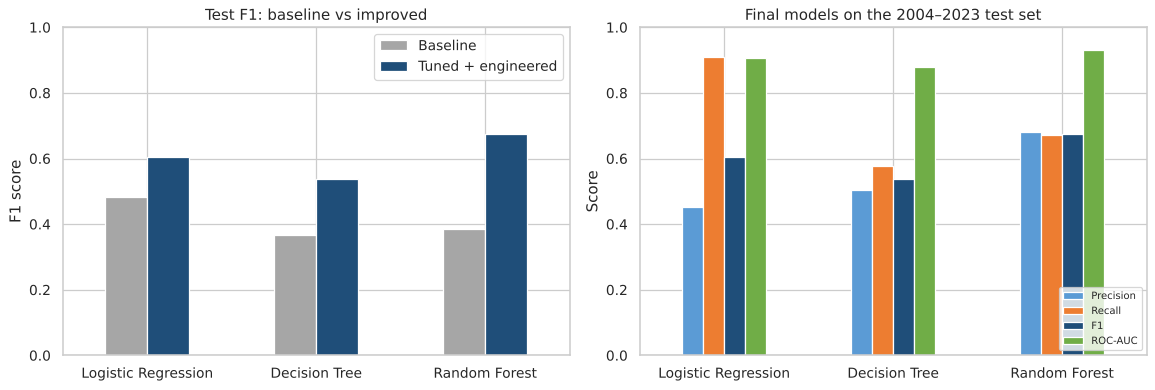

In [16]:
comp = pd.concat({"Baseline": pd.DataFrame(baseline).T["F1"], "Tuned + engineered": final_table["F1"]}, axis=1)
print(comp.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
comp.plot.bar(ax=axes[0], color=["#a6a6a6", "#1f4e79"], rot=0)
axes[0].set_title("Test F1: baseline vs improved"); axes[0].set_ylabel("F1 score"); axes[0].set_ylim(0, 1)
final_table[["Precision", "Recall", "F1", "ROC-AUC"]].plot.bar(ax=axes[1], rot=0,
        color=["#5b9bd5", "#ed7d31", "#1f4e79", "#70ad47"])
axes[1].set_title("Final models on the 2004–2023 test set"); axes[1].set_ylim(0, 1); axes[1].set_ylabel("Score")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig5_model_comparison.png", dpi=150); plt.show()

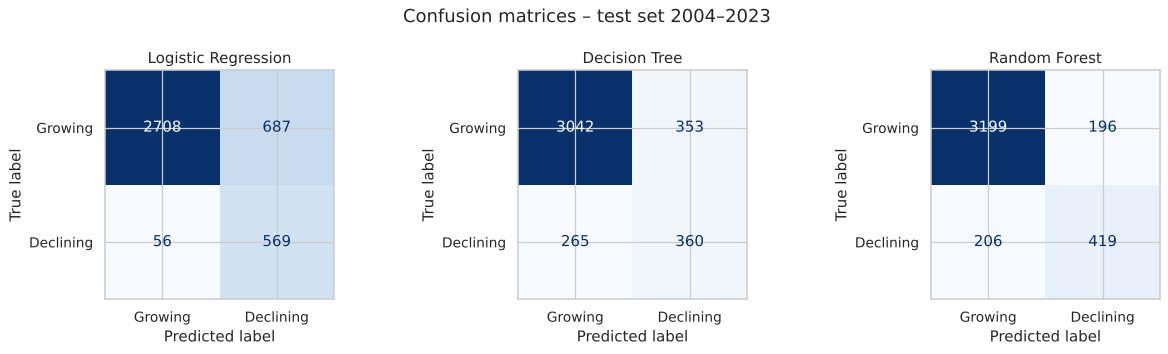

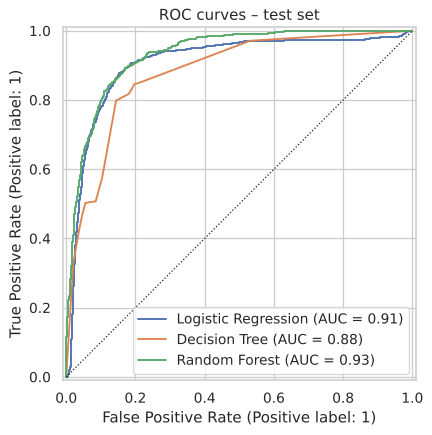

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, m) in zip(axes, tuned.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_te2, y_te, display_labels=["Growing", "Declining"],
                                          cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.suptitle("Confusion matrices – test set 2004–2023"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig6_confusion.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for name, m in tuned.items():
    RocCurveDisplay.from_estimator(m, X_te2, y_te, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_title("ROC curves – test set")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig7_roc.png", dpi=150); plt.show()

## 7. Interpretation

                   Gini importance  Permutation (test F1 drop)
CNMR_prev5                  0.2725                      0.1865
PopSexRatio                 0.0948                      0.1513
NRR                         0.1623                      0.1077
MedianAgePop                0.0479                      0.0401
TFR                         0.0929                      0.0217
LEx_gap                     0.0256                      0.0173
PopDensity                  0.0321                      0.0128
MedianAge_change5           0.0338                      0.0070
Q0040                       0.0083                      0.0045
Q1550                       0.0275                      0.0012
LE65                        0.0104                      0.0012
IMR                         0.0150                     -0.0001
LE80                        0.0146                     -0.0008
SRB                         0.0180                     -0.0009
LEx                         0.0094                     

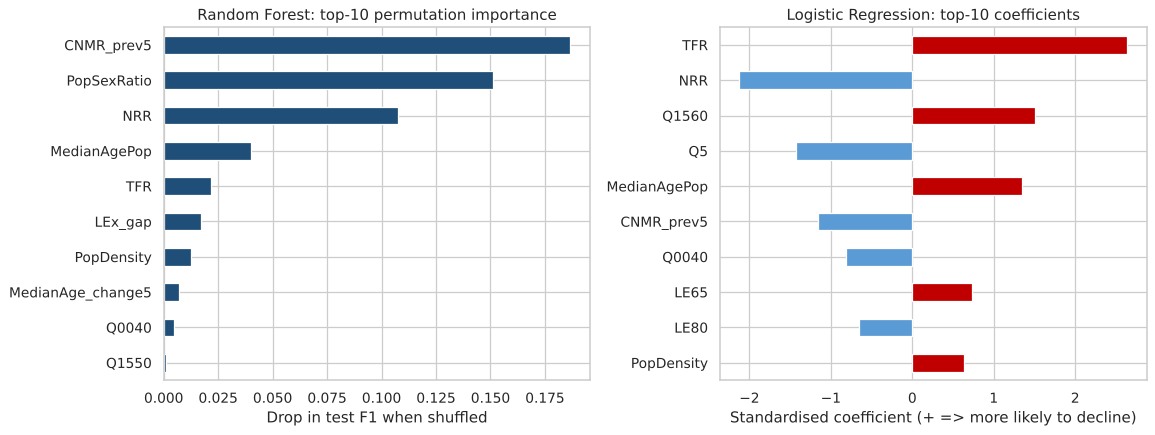

In [18]:
rf = tuned["Random Forest"]
perm = permutation_importance(rf, X_te2, y_te, scoring="f1", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"Gini importance": rf.feature_importances_, "Permutation (test F1 drop)": perm.importances_mean},
                   index=ALL_FEATURES).sort_values("Permutation (test F1 drop)", ascending=False)
print(imp.round(4))
lr_coef = pd.Series(tuned["Logistic Regression"].named_steps["clf"].coef_[0], index=ALL_FEATURES).sort_values(key=abs, ascending=False)
print("\nLogistic Regression standardised coefficients:"); print(lr_coef.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
imp["Permutation (test F1 drop)"].head(10)[::-1].plot.barh(ax=axes[0], color="#1f4e79")
axes[0].set_title("Random Forest: top-10 permutation importance"); axes[0].set_xlabel("Drop in test F1 when shuffled")
lr_coef.head(10)[::-1].plot.barh(ax=axes[1], color=["#c00000" if v > 0 else "#5b9bd5" for v in lr_coef.head(10)[::-1]])
axes[1].set_title("Logistic Regression: top-10 coefficients"); axes[1].set_xlabel("Standardised coefficient (+ => more likely to decline)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig8_importance.png", dpi=150); plt.show()

In [19]:
best = final_table["F1"].idxmax()
print("Best model on test F1:", best)
print(classification_report(y_te, tuned[best].predict(X_te2), target_names=["Growing", "Declining"], digits=3))
# Where does the best model go wrong? Countries with most errors on the test set
err = test.assign(pred=tuned[best].predict(X_te2))
err = err[err.pred != err.Declining]
print(err.groupby(["Location"]).size().sort_values(ascending=False).head(10))

Best model on test F1: Random Forest
              precision    recall  f1-score   support

     Growing      0.940     0.942     0.941      3395
   Declining      0.681     0.670     0.676       625

    accuracy                          0.900      4020
   macro avg      0.810     0.806     0.808      4020
weighted avg      0.899     0.900     0.900      4020

Location
El Salvador           17
Japan                 14
Russian Federation    13
Croatia               13
Nepal                 12
Albania               11
Cuba                  11
Greece                11
North Macedonia       11
Singapore             10
dtype: int64


## Appendix charts

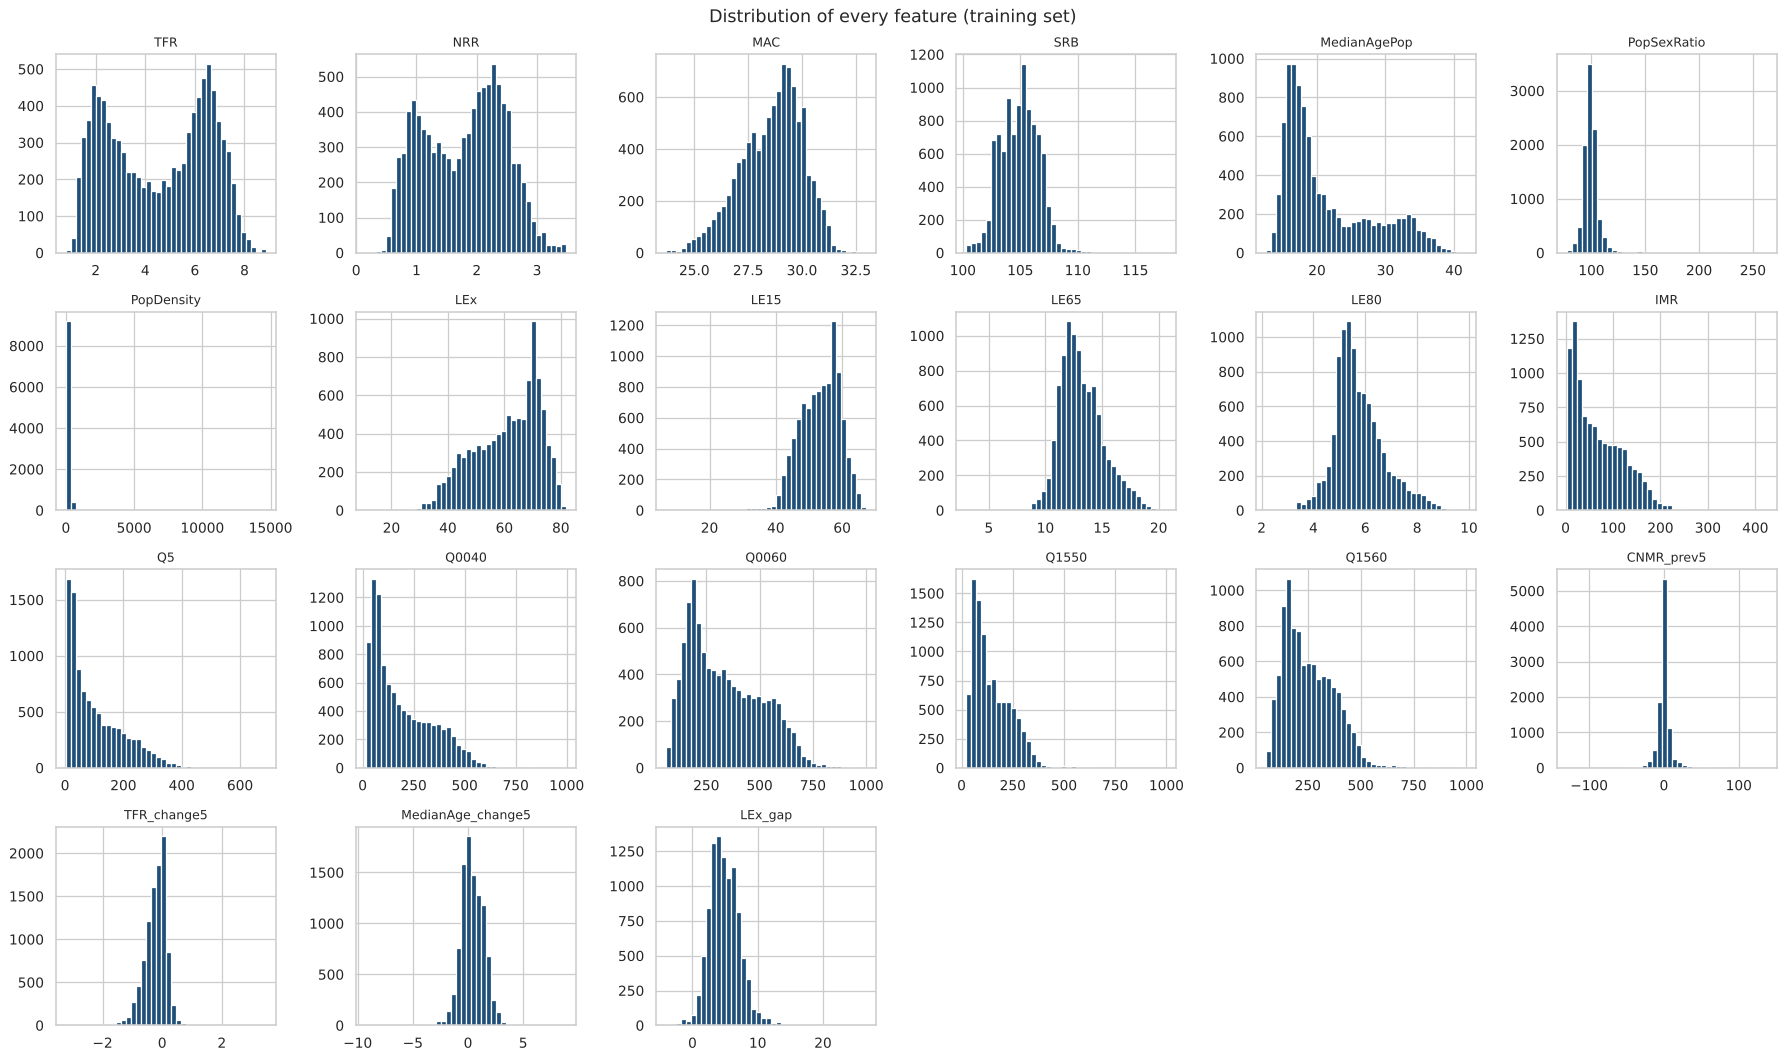

In [20]:
fig, axes = plt.subplots(4, 6, figsize=(20, 12)); axes = axes.ravel()
for ax, col in zip(axes, ALL_FEATURES):
    ax.hist(train[col], bins=40, color="#1f4e79", edgecolor="white"); ax.set_title(col, fontsize=10)
for ax in axes[len(ALL_FEATURES):]: ax.axis("off")
fig.suptitle("Distribution of every feature (training set)", fontsize=14)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/figA1_all_hist.png", dpi=120); plt.show()

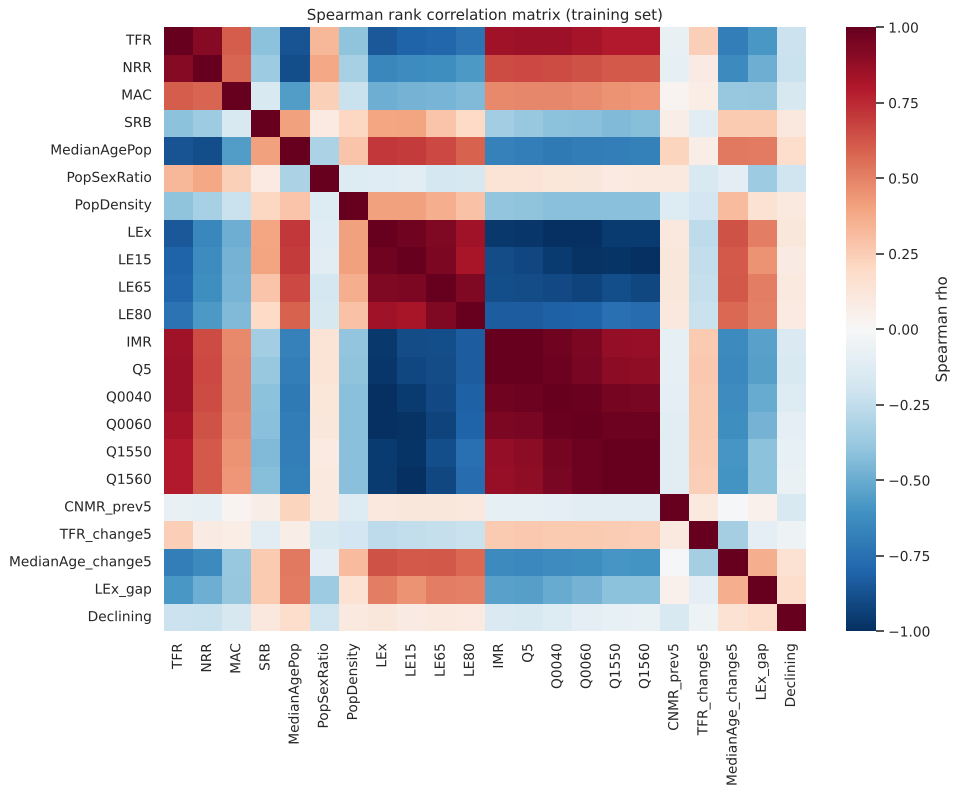

In [21]:
sp = train[ALL_FEATURES + ["Declining"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(sp, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Spearman rho"})
ax.set_title("Spearman rank correlation matrix (training set)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/figA2_spearman.png", dpi=150); plt.show()

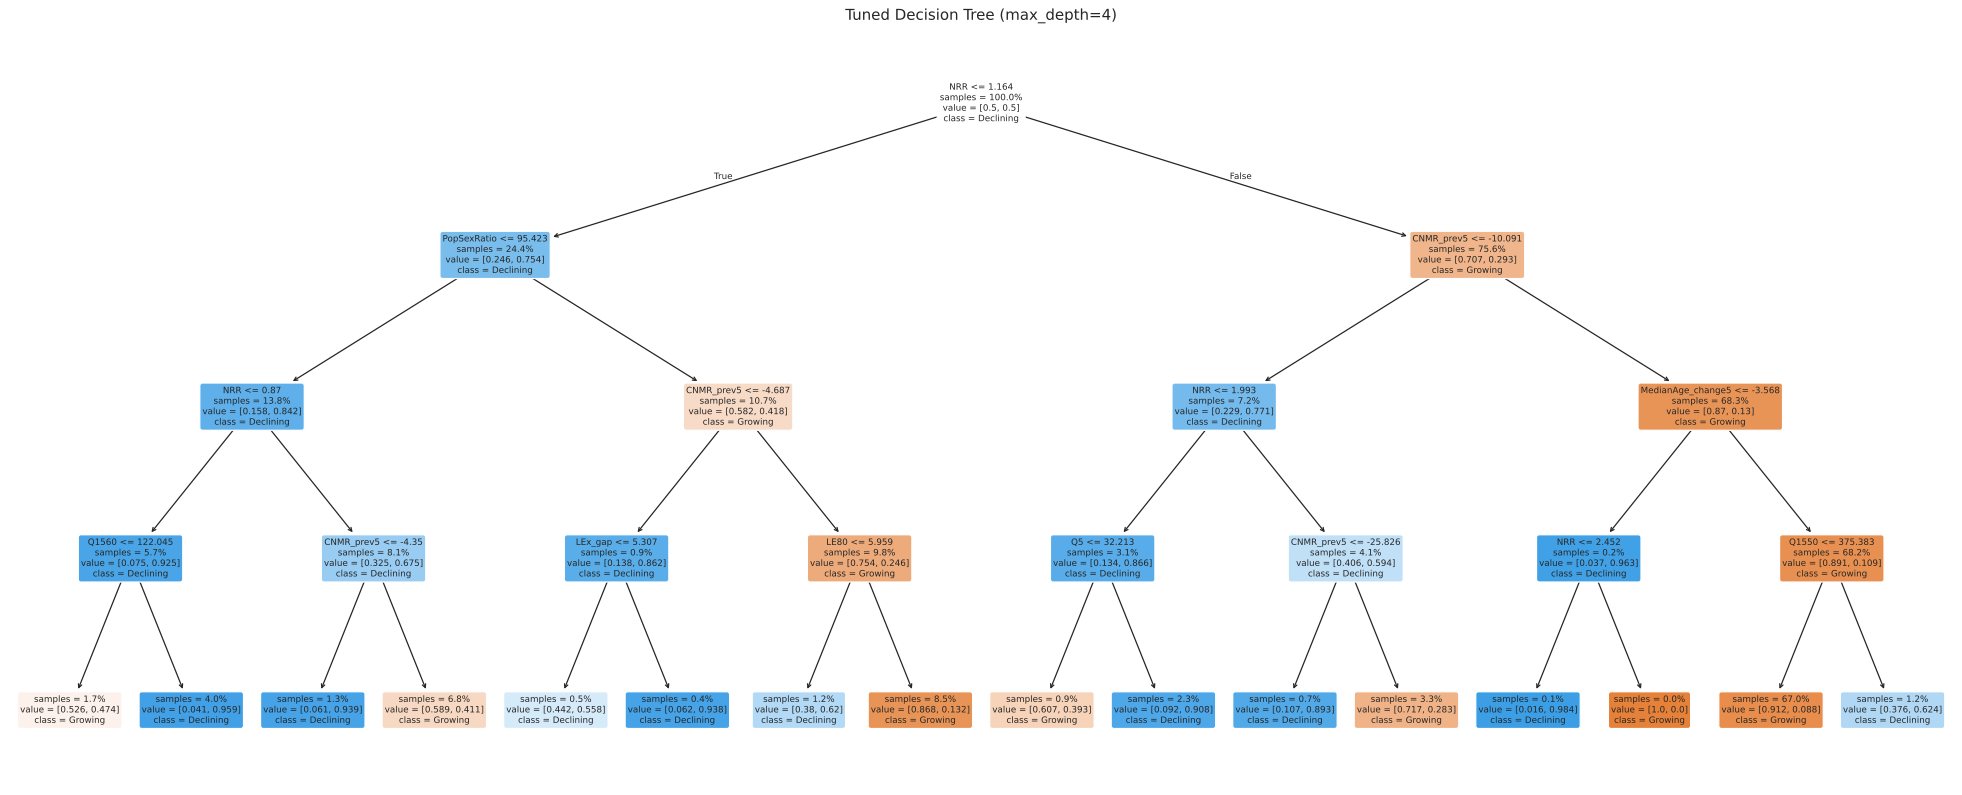

In [22]:
from sklearn.tree import plot_tree
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tuned["Decision Tree"], feature_names=ALL_FEATURES, class_names=["Growing", "Declining"],
          filled=True, rounded=True, fontsize=7, ax=ax, impurity=False, proportion=True)
ax.set_title("Tuned Decision Tree (max_depth=4)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/figA3_tree.png", dpi=130); plt.show()

In [23]:
import json
results = {"rows_model": len(model_df), "rows_train": len(train), "rows_test": len(test),
           "pos_train": float(train.Declining.mean()), "pos_test": float(test.Declining.mean()),
           "n_countries": int(model_df.Location.nunique()),
           "seen": seen, "seen_tuned": seen_tuned, "baseline": baseline, "final": final, "best_params": {k: {a: (None if b is None else b) for a, b in v.items()} for k, v in best_params.items()},
           "cv_best": cv_best, "cv_table": cv_table.to_dict(orient="index")}
json.dump(results, open("results.json", "w"), indent=2, default=str)
print("saved results.json")

saved results.json
